# Map flux

 ### 1) Read L(nu;z).
 
 ### 2) Find closest freq to nu_target and collapse L(nu;z) --> L(z).
 
 ### 3) Build sky map (x,y) in mas units.
 
 ### 4) Evaluate L(x,y) from L(z), assuming optically thin jet and homogeneous distribution of luminosity over height slices. 
 
 ### 5) Convert luminosity to flux and mirror in x.
 
 ### 6) Convolve with Gaussian elliptical beam.
 
 ### 7) Plotting.

### Import modules

In [1]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import Colormap

### User parameters

In [2]:
incl = 17.0 * np.pi / 180.0
Nx = 32
nu_target_GHz = 43.0
f_Ny = 0.15 # Nyquist frequency (< 0.6)
#sigma_x, sigma_y = 0.31, 0.31 # Beam resolution in [mas] 
sigma_x, sigma_y = 0.1, 0.1 # Mock value for testing
#co = sqrt(8.d0*log(2.d0))       ! difference between sigma and theta!, theta = sigma*co

### Define some constants

In [3]:
h = 6.6260755e-27
eV = 1.602176e-12
kpc = 3.0856e21
distance = 16.8e3
convert = 206265e3/(distance*kpc) # image to angular size (mas)
flux = 1.e26*(h/eV)/(4.0*np.pi*(distance*kpc)**2) # L[erg/s/erg] -> F[mJy]

### Define some useful functions

In [4]:
def read_SEDsyn_cuts(filename='./../Code/SEDsyn_cuts_ord.dat'):
    fname = filename
    #fname format: Esy, Lsy*Esy, Labssy, l
    data = np.loadtxt(fname).transpose()
    
    NSED_sy = 0
    value = data[3][0]
    while data[3][NSED_sy] == value:
        NSED_sy += 1
    Ns = np.size(data[3])//NSED_sy
    print("(Ns, NSED_sy) = (", Ns, ", ", NSED_sy, ")")
    Esy = data[0][:NSED_sy]
    Lsy = np.zeros((Ns, NSED_sy))
    for i in range(Ns):
        Lsy[i] = data[2][i*NSED_sy:(i+1)*NSED_sy] / data[0][:NSED_sy]
    
    return Esy, Lsy

In [5]:
def get_Lsyn_z( Esy, Lsy, nu_target):
    E_nu_target = h * nu_target * 1e9 / eV
    # Step through energies:
    i_nu_target = 0
    while Esy[i_nu_target] < E_nu_target:
        i_nu_target += 1
    
    # Make a linear interpolation
    slope = (Lsy[:, i_nu_target] - Lsy[:, i_nu_target-1]) / (Esy[i_nu_target] - Esy[i_nu_target-1])
    Ltarget = Lsy[:, i_nu_target-1] + slope * (E_nu_target - Esy[i_nu_target-1])
    Ltarget[Ltarget == 0] = 1e-10 # Mock value to avoid dividing by zero
    return Ltarget

In [6]:
def get_z_rz( filename='./../Code/quant_FF.dat'):
    # These values are defined in the observer frame
    fname = filename
    data = np.loadtxt(fname, usecols=(0, 2))
    return data[:, 0], data[:, 1]

In [7]:
def make_F_map( nu, Nx ):
    Esy, Lsy = read_SEDsyn_cuts()
    L_z = get_Lsyn_z( Esy, Lsy, nu )
    z, r_z = get_z_rz()
    dz = z[1] - z[0]
    
    if dz*np.sin(incl) > 2.0*r_z[-1]*np.cos(incl): #si se cumple para el último se cumple para todos
        x = np.linspace( 0, r_z[-1], Nx) * convert
        dx = x[1] - x[0]
        print('Entramos a lateral_projection')
        y_map = z * np.sin(incl) * convert
        r_z_proj = r_z * convert
        L_map = np.ones(( len( x), len( y_map))) * 0
        for j in range( len( y_map)):
            for i in range( len( x)):
                if x[ i] < r_z_proj[ j]:
                    L_map[i,j] = 2.0 * L_z[ j] * np.sqrt( r_z_proj[ j]**2.0 - x[ i]**2.0) / (np.pi * r_z_proj[ j]**2.0)
                    L_map[i,j] = L_map[i,j] * dx
            # Correction factor for better conservation of luminosity
            temp = np.sum( L_map[:,j])
            L_map[:,j] = L_map[:,j] * 0.5*L_z[j] / temp
    else:
        print('Entramos a faceon_projection')
        dy = 1.0 * r_z[0] * np.cos(incl) * convert # delta_y < 2*r_j*cos(i) para todo r_j
        dx = 1.0 * r_z[0] * convert
        y_max = (z[-1]*np.sin(incl) + r_z[-1]*np.cos(incl)) * convert
        x_max = r_z[-1] * convert
        Ny = int(y_max/dy)
        Nx = int(x_max/dx)
        print('Ny = ' + str(Ny))
        print('Nx = ' + str(Nx))
        y_map = np.linspace(0, y_max, Ny )
        x_map = np.linspace(0, x_max, Nx )

        L_map = np.zeros((np.size(x_map), np.size(y_map)))

        x_double = np.ones_like(L_map)
        y_double = np.ones_like(L_map)
        dx = x_map[1] - x_map[0]
        dy = y_map[1] - y_map[0]
        for j in range(len(y_map)):
            x_double[:, j] = x_map
        for i in range(len(x_map)):
            y_double[i, :] = y_map

        ellipses = []
        iy_start = 0
        L_tot = 0.
        for iz in range(np.size(L_z)):
            center = z[iz] * np.sin(incl) * convert
            a_semiaxis = r_z[iz] * convert
            b_semiaxis = r_z[iz] * np.cos(incl) * convert
            inv_area = np.power(np.pi*a_semiaxis*b_semiaxis, -1)
            # Ecuacion: (x/a)²+((y-z.sin(i))/b)²=1
            ell = []
            for s in np.linspace(0, 2.*np.pi, 30):
                ell.append([a_semiaxis*np.cos(s), b_semiaxis*np.sin(s)+center])
            ellipses.append(ell)
            L_local = np.where( np.square(x_double/a_semiaxis) + np.square((y_double-center)/b_semiaxis) < 1.,
                     1, 0) * L_z[iz] * min(dy*dx*inv_area, 0.5)
            renorm = 1./(2.*np.sum(L_local)/L_z[iz]) # Renormalization factor to conserve flux
            L_local = L_local*renorm
            L_map += L_local
            L_local = np.sum(L_local)
            L_tot += L_local
    print( 'L_proj/L_pre-proj = ' + str(2*L_tot/np.sum(L_z)) )

    return x_map, y_map, L_map

In [8]:
def Flux_mirror_map( x_map, L_map ):
    Nx = len(x_map)
    x_map22 = np.ones( 2*Nx )
    F_map = np.ones( (2*len(L_map[:, 0]), len(L_map[0, :])) )

    x_map22[:Nx] = -np.flip(x_map)
    x_map22[Nx:] = x_map
    F_map[:Nx, :] = np.flip(L_map, axis=0) * flux
    F_map[Nx:, :] = L_map*flux
    return x_map22, F_map

In [9]:
def Convolve_map( x_map, x_map22, y_map, F_map, sigma_x, sigma_y ):    
    # The number of points in the convolved map depends on the beam size and the size of the original map.

    # Extremes of the convolved map
    y_min_c = y_map[0] - 4. * sigma_y # 5 beams to the left of the jet base
    y_max_c = y_map[-1] + 4. * sigma_y # 5 beams to the right of the jet end point
    x_min_c = x_map[0] - 3. * sigma_x # 3 beams above the jet lateral end point
    x_max_c = x_map[-1] + 3. * sigma_x # 3 beams below the jet lateral end point

    # Size of the convolved map
    ancho_x = x_max_c - x_min_c
    ancho_y = y_max_c - y_min_c 

    # Size of each cell of the convolved map
    Dx_c = f_Ny*sigma_x
    Dy_c = f_Ny*sigma_y

    # Number of cells of the convolved map
    Nx_c = int(ancho_x/Dx_c)
    Ny_c = int(ancho_y/Dy_c)

    # Position of the cells of the convolved map
    x_c = np.linspace( x_min_c, x_max_c, Nx_c)
    y_c = np.linspace( y_min_c, y_max_c, Ny_c)

    print('Dimension of the convolution grid: ' + str(Nx_c) + 'x' + str(Ny_c))
    
    F_map_c = np.ones((Nx_c, Ny_c))

    w_x = 0.5/sigma_x**2 # weight for x distance
    w_y = 0.5/sigma_y**2 # weight for y distance

    x_double = np.ones_like(F_map)
    y_double = np.ones_like(F_map)
    for j in range(len(y_map)):
        x_double[:, j] = x_map22
    for i in range(len(x_map22)):
        y_double[i, :] = y_map

    for i in range(Nx_c):
        for j in range(Ny_c):
            # Gaussian: (1/(2pi*sigma_x*sigma_y)) * exp(-((x-x_c)²/2.sigma_x² + (y-y_c)²/2.sigma_y²))
            gaussian = np.exp(-(np.square(x_double-x_c[i])*w_x + np.square(y_double-y_c[j])*w_y))
            F_map_c[i, j] = np.sum(F_map*gaussian)
            
    S_pre = np.sum(F_map)
    print('Pre-conv: S(GHz) = ' + str(S_pre) + ' mJy')
    # Gaussian beam -> exp(...)/(sigma*sqrt(2*pi)), both in x and y
    A_beam = 2 * np.pi * sigma_x * sigma_y     # = Gaussian normalization factor 
    A_cell = Dx_c * Dy_c              # cell sample size
    mJy_beam = A_cell/A_beam          # Transform mJy/beam -> mJy (for checks)
    S_post = np.sum(F_map_c) * mJy_beam
    print('Post-conv: S(GHz) = ' + str(S_post) + ' mJy')
    print('post/pre = ' + str(S_post/S_pre) )
    
    return x_c, y_c, F_map_c

In [10]:
def Make_spix_map( x_c, y_c, nu1, F_map1, nu2, F_map2):
    spix_map = np.zeros((len(x_c), len(y_c)))
    log_nu2nu1 = np.log(nu2/nu1)

    for i in range(len(x_c)):
        for j in range(len(y_c)):
            if ( F_map2[i,j] > 1e-3 and F_map1[i,j] > 2e-2 ): # Define according to rms of maps! (e.g. at least 20 uJy)
                   spix_map[i,j] = np.log( F_map2[i,j]/F_map1[i,j] ) / log_nu2nu1
    return spix_map

### Use the subroutines to make the synthetic intensity maps and the spix map

In [11]:
nu1 = 22.0 # GHz
x_map, y_map, L_map1 = make_F_map( nu1, Nx )
# First mirror and convert to fluxes
x_map22, F_map1 = Flux_mirror_map( x_map, L_map1)
x_c, y_c, F_map_c1 = Convolve_map( x_map, x_map22, y_map, F_map1, sigma_x, sigma_y )

(Ns, NSED_sy) = ( 200 ,  150 )
Entramos a faceon_projection
Ny = 516
Nx = 21
L_proj/L_pre-proj = 0.9999999999999999
Dimension of the convolution grid: 42x103
Pre-conv: S(GHz) = 1781.3291958680145 mJy
Post-conv: S(GHz) = 1699.5502929516852 mJy
post/pre = 0.9540910781084011


In [12]:
nu2 = 43.0 # GHz
x_map, y_map, L_map2 = make_F_map( nu2, Nx )
# First mirror and convert to fluxes
x_map22, F_map2 = Flux_mirror_map( x_map, L_map2)
x_c, y_c, F_map_c2 = Convolve_map( x_map, x_map22, y_map, F_map2, sigma_x, sigma_y )

(Ns, NSED_sy) = ( 200 ,  150 )
Entramos a faceon_projection
Ny = 516
Nx = 21
L_proj/L_pre-proj = 0.9999999999999993
Dimension of the convolution grid: 42x103
Pre-conv: S(GHz) = 1515.2190407149533 mJy
Post-conv: S(GHz) = 1445.6573771151384 mJy
post/pre = 0.9540913480291322


In [13]:
spix_map = Make_spix_map( x_c, y_c, nu1, F_map_c1, nu2, F_map_c2)

In [14]:
nice_fonts = {
        # Use LaTeX to write all text
        "text.usetex": False,
        "font.family": 'serif',
        # Use 10pt font in plots, to match 10pt font in document
        "axes.labelsize": 16,
        "font.size": 16,
        "axes.linewidth":1,
        "axes.titlesize":20,
        # Make the legend/label fonts a little smaller
        "legend.fontsize": 10,
        "xtick.labelsize": 14,
        "ytick.labelsize": 14,
}
matplotlib.rcParams.update(nice_fonts)

#### Unconvolved flux map:

<ipython-input-15-e458cc1cca5d>:13: RuntimeWarning: divide by zero encountered in log10
  CS = ax1.contourf( y_map, x_map, np.log10(L_map1), cmap=cmap, levels=100, extend="both")
<ipython-input-15-e458cc1cca5d>:14: RuntimeWarning: divide by zero encountered in log10
  CS2 = ax2.contourf( y_map, x_map, np.log10(L_map2), cmap=cmap, levels=100, extend="both")


<Figure size 432x288 with 0 Axes>

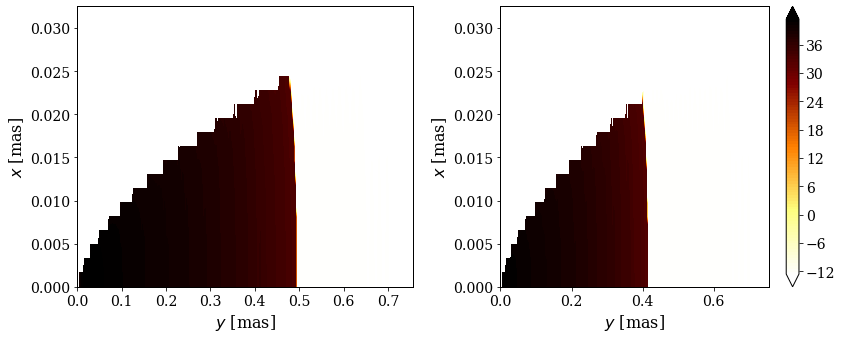

In [15]:
plt.clf()
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
ax1.set_xlabel(r"$y$ [mas]")
ax1.set_ylabel(r"$x$ [mas]")
ax1.set_xlim([0, y_map[-1]])
ax1.set_ylim([x_map[0], x_map[-1]])
ax2.set_xlabel(r"$y$ [mas]")
ax2.set_ylabel(r"$x$ [mas]")
ax2.set_xlim([0, y_map[-1]])
ax2.set_ylim([x_map[0], x_map[-1]])
cmap  = plt.cm.afmhot_r
#cmap.set_label(r"$S_\nu$ [mJy]")
CS = ax1.contourf( y_map, x_map, np.log10(L_map1), cmap=cmap, levels=100, extend="both")
CS2 = ax2.contourf( y_map, x_map, np.log10(L_map2), cmap=cmap, levels=100, extend="both")
# MEJOR USAR x_map22 Y F_map ???

plt.tight_layout()
fig.colorbar(CS)
#AGREGAR TITULOS/ETIQUETAS DE LA FRECUENCIA DE CADA MAPA; TAMBIEN RESTRINGIR EL RANGO DEL EJE DE COLOR

#### Convolved flux map:

<Figure size 432x288 with 0 Axes>

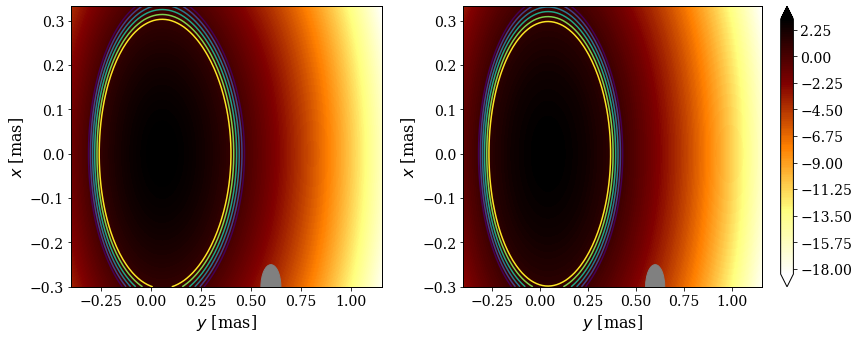

In [16]:
from matplotlib.patches import Ellipse

plt.clf()
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={'width_ratios': [1, 1.2]})
ax1.set_xlabel(r"$y$ [mas]")
ax1.set_ylabel(r"$x$ [mas]")
ax1.set_xlim([y_c[0], y_c[-1]])
ax1.set_ylim([x_c[0], x_c[-1]])
ax2.set_xlabel(r"$y$ [mas]")
ax2.set_ylabel(r"$x$ [mas]")
ax2.set_xlim([y_c[0], y_c[-1]])
ax2.set_ylim([x_c[0], x_c[-1]])
cmap  = plt.cm.afmhot_r
#cmap.set_label(r"$S_\nu$ [mJy beam$^{-1}$]")
CS_conv = ax1.contourf( y_c, x_c, np.log10(F_map_c1), cmap=cmap, levels=200, extend="both")
CS_conv = ax2.contourf( y_c, x_c, np.log10(F_map_c2), cmap=cmap, levels=200, extend="both")

#Agregar contornos a (1, 1.4, 2, 2.8...)*3 mJy beam^-1.
obs_cont = np.log10([1*3, 1.4*3, 2*3, 2.8*3, 4*3, 5.6*3]) # HACERLOS EN GRIS!
plot_cont = ax1.contour( y_c, x_c, np.log10(F_map_c1), levels=obs_cont, extend="both")
plot_cont2 = ax2.contour( y_c, x_c, np.log10(F_map_c2), levels=obs_cont, extend="both")

el = Ellipse((0.6, -0.3), sigma_y, sigma_x, color='grey')
el2 = Ellipse((0.6, -0.3), sigma_y, sigma_x, color='grey')

ax1.add_patch(el)
ax2.add_patch(el2)

plt.tight_layout()
fig.colorbar( CS_conv)

<Figure size 432x288 with 0 Axes>

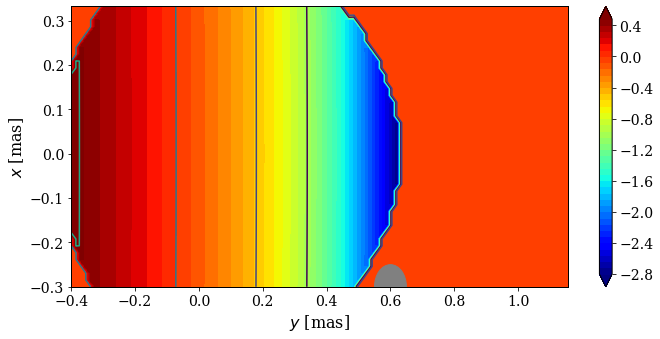

In [17]:
plt.clf()
fig, ax = plt.subplots(1, 1, figsize=(10, 5))
ax.set_xlabel(r"$y$ [mas]")
ax.set_ylabel(r"$x$ [mas]")
ax.set_xlim([y_c[0], y_c[-1]])
ax.set_ylim([x_c[0], x_c[-1]])
cmap  = plt.cm.jet # CAMBIARLO POR UNO MEJOR!
CS_conv = ax.contourf( y_c, x_c, spix_map, cmap=cmap, levels=50, extend="both")
#PONER EN BLANCO DONDE NO HAY DATOS

#Agregar contornos a valores representativos
obs_cont = ([-1.0, -0.5, 0.0, 0.5, 1.0, 1.5]) # HACERLOS EN GRIS!
plot_cont = ax.contour( y_c, x_c, spix_map, levels=obs_cont, extend="both")

el = Ellipse((0.6, -0.3), sigma_y, sigma_x, color='grey')

ax.add_patch(el)

plt.tight_layout()
fig.colorbar( CS_conv)

# BORRAR TODO LO DE ABAJO?

### 1) Read L(nu;z).

In [18]:
Esy, Lsy = read_SEDsyn_cuts()

(Ns, NSED_sy) = ( 200 ,  150 )


### 2) Find closest freq to nu_target and collapse L(nu;z) --> L(z).

In [19]:
L_z = get_Lsyn_z( Esy, Lsy, nu_target_GHz)
#print(L_z)

 ### 3) Build sky map (x,y) in mas units.

In [20]:
z, r_z = get_z_rz()
y_map = z * np.sin( incl) * convert
x = np.linspace( 0, r_z[-1], Nx) * convert
dx = x[1] - x[0]

 ### 4) Evaluate L(x,y) from L(z), assuming optically thin jet and homogeneous distribution of luminosity over height slices. 

In [21]:
if 1:
    print('Entramos a lateral_projection')
    y_map = z * np.sin(incl) * convert
    r_z_proj = r_z * convert
    L_map = np.zeros(( len( x), len( y_map)))
    for j in range( len( y_map)):
        for i in range( len( x)):
            if x[ i] < r_z_proj[ j]:
                L_map[i,j] = 2.0 * L_z[ j] * np.sqrt( r_z_proj[ j]**2.0 - x[ i]**2.0) / (np.pi * r_z_proj[ j]**2.0)
                L_map[i,j] = L_map[i,j] * dx
           # Correction factor for better conservation of luminosity
        temp = np.sum( L_map[:,j])
        L_map[:,j] = L_map[:,j] * 0.5*L_z[j] / temp
if 1:
    print('Entramos a faceon_projection')
    dy = 2.0 * r_z[0] * np.cos(incl) * convert # delta_y < 2*r_j*cos(i) para todo r_j
    dx = 2.0 * r_z[0] * convert
    y_max = (z[-1]*np.sin(incl) + r_z[-1]*np.cos(incl)) * convert
    x_max = r_z[-1] * convert
    Ny2 = int(y_max/dy)
    Nx2 = int(x_max/dx)
    print('Ny = ' + str(Ny2))
    print('Nx = ' + str(Nx2))
    y_map2 = np.linspace(0, y_max, Ny2 )
    x_map2 = np.linspace(0, x_max, Nx2 )

    L_map2 = np.zeros((np.size(x_map2), np.size(y_map2)))

    x_double = np.ones_like(L_map2)
    y_double = np.ones_like(L_map2)
    dx = x_map2[1] - x_map2[0]
    dy = y_map2[1] - y_map2[0]
    for j in range(len(y_map2)):
        x_double[:, j] = x_map2
    for i in range(len(x_map2)):
        y_double[i, :] = y_map2

    ellipses = []
    iy_start = 0
    L_tot = 0.
    for iz in range(np.size(L_z)):
        center = z[iz] * np.sin(incl) * convert
        a_semiaxis = r_z[iz] * convert
        b_semiaxis = r_z[iz] * np.cos(incl) * convert
        inv_area = np.power(np.pi*a_semiaxis*b_semiaxis, -1)
        # Ecuacion: (x/a)²+((y-z.sin(i))/b)²=1
        ell = []
        for s in np.linspace(0, 2.*np.pi, 30):
            ell.append([a_semiaxis*np.cos(s), b_semiaxis*np.sin(s)+center])
        ellipses.append(ell)
        L_local = np.where( np.square(x_double/a_semiaxis) + np.square((y_double-center)/b_semiaxis) < 1.,
                 1, 0) * L_z[iz] * min(dy*dx*inv_area, 0.5)
        renorm = 1./(2.*np.sum(L_local)/L_z[iz]) # Renormalization factor to conserve flux
        L_local = L_local*renorm
        L_map2 += L_local
        L_local = np.sum(L_local)
        L_tot += L_local
print( 'L_proj/L_pre-proj = ' + str(2*L_tot/np.sum(L_z)) )

Entramos a lateral_projection
Entramos a faceon_projection
Ny = 258
Nx = 10
L_proj/L_pre-proj = 0.9999999999999993


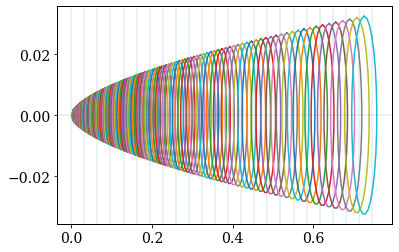

In [22]:
# SHOW ELIPSES

yyy = np.array(ellipses)
#for i in range(len(ellipses)):
for e in yyy[::1]:
    plt.plot(e[:, 1], e[:, 0])
for xx in x_map2[::11]:
    plt.axhline(xx, lw=0.2)
for yy in y_map2[::11]:
    plt.axvline(yy, lw=0.2)

 ### 5) Convert luminosity to flux and mirror in x.

In [23]:
x_map = np.ones( 2*len(x))
x_map22 = np.ones( 2*len(x_map2))
F_map = np.ones( (2*len(L_map[:, 0]), len(L_map[0, :])))
F_map2 = np.ones( (2*len(L_map2[:, 0]), len(L_map2[0, :])) )

x_map[:Nx] = -np.flip(x)
x_map[Nx:] = x
F_map[:Nx, :] = np.flip(L_map, axis=0) * flux
F_map[Nx:, :] = L_map * flux 
x_map22[:Nx2] = -np.flip(x_map2)
x_map22[Nx2:] = x_map2
F_map2[:Nx2, :] = np.flip(L_map2, axis=0) * flux
F_map2[Nx2:, :] = L_map2*flux

print(Nx,Nx2)
print(x_map22)

32 10
[-0.03251573 -0.02890287 -0.02529001 -0.02167715 -0.0180643  -0.01445144
 -0.01083858 -0.00722572 -0.00361286 -0.          0.          0.00361286
  0.00722572  0.01083858  0.01445144  0.0180643   0.02167715  0.02529001
  0.02890287  0.03251573]


###  6) Convolve with Gaussian elliptical beam.

In [24]:
# The number of points in the convolved map depends on the beam size and the size of the original map.

# Extremes of the convolved map
y_min_c = y_map[0] - 4. * sigma_y # 5 beams to the left of the jet base
y_max_c = y_map[-1] + 4. * sigma_y # 5 beams to the right of the jet end point
x_min_c = x_map[0] - 3. * sigma_x # 3 beams above the jet lateral end point
x_max_c = x_map[-1] + 3. * sigma_x # 3 beams below the jet lateral end point

# Size of the convolved map
ancho_x = x_max_c - x_min_c
ancho_y = y_max_c - y_min_c 

# Size of each cell of the convolved map
Dx_c = f_Ny*sigma_x
Dy_c = f_Ny*sigma_y

# Number of cells of the convolved map
Nx_c = int(ancho_x/Dx_c)
Ny_c = int(ancho_y/Dy_c)

# Position of the cells of the convolved map
x_c = np.linspace( x_min_c, x_max_c, Nx_c)
y_c = np.linspace( y_min_c, y_max_c, Ny_c)

print('Dimension of the convolution grid: ' + str(Nx_c) + 'x' + str(Ny_c))

Dimension of the convolution grid: 44x101


In [25]:
F_map_c = np.ones((Nx_c, Ny_c))
F_map_c2 = np.ones((Nx_c, Ny_c))

w_x = 0.5/sigma_x**2 # weight for x distance
w_y = 0.5/sigma_y**2 # weight for y distance

x_double = np.ones_like(F_map)
y_double = np.ones_like(F_map)
for j in range(len(y_map)):
    x_double[:, j] = x_map
for i in range(len(x_map)):
    y_double[i, :] = y_map
    
x_double2 = np.ones_like(F_map2)
y_double2 = np.ones_like(F_map2)
for j in range(len(y_map2)):
    x_double2[:, j] = x_map22
for i in range(len(x_map22)):
    y_double2[i, :] = y_map2

for i in range(Nx_c):
    print(i)
    for j in range(Ny_c):
        # Gaussian: (1/(2pi*sigma_x*sigma_y)) * exp(-((x-x_c)²/2.sigma_x² + (y-y_c)²/2.sigma_y²))
        gaussian = np.exp(-(np.square(x_double-x_c[i])*w_x + np.square(y_double-y_c[j])*w_y))
        gaussian2 = np.exp(-(np.square(x_double2-x_c[i])*w_x + np.square(y_double2-y_c[j])*w_y))
        F_map_c[i, j] = np.sum(F_map*gaussian)
        F_map_c2[i, j] = np.sum(F_map2*gaussian2)

0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43


In [26]:
S_pre = np.sum(F_map)
print('Lateral Pre-conv: S(GHz) = ' + str(S_pre) + ' mJy')
# Gaussian beam -> exp(...)/(sigma*sqrt(2*pi)), both in x and y
A_beam = 2 * np.pi * sigma_x * sigma_y     # = Gaussian normalization factor 
A_cell = Dx_c * Dy_c              # cell sample size
mJy_beam = A_cell/A_beam          # Transform mJy/beam -> mJy (for checks)
S_post = np.sum(F_map_c) * mJy_beam
print('Lateral Post-conv: S(GHz) = ' + str(S_post) + ' mJy')
print('Lateral post/pre = ' + str(S_post/S_pre) )

S_pre = np.sum(F_map2)
print('Face-on Pre-conv: S(GHz) = ' + str(S_pre) + ' mJy')
# Gaussian beam -> exp(...)/(sigma*sqrt(2*pi)), both in x and y
A_beam = 2 * np.pi * sigma_x * sigma_y     # = Gaussian normalization factor 
A_cell = Dx_c * Dy_c              # cell sample size
mJy_beam = A_cell/A_beam          # Transform mJy/beam -> mJy (for checks)
S_post = np.sum(F_map_c2) * mJy_beam
print('Face-on Post-conv: S(GHz) = ' + str(S_post) + ' mJy')
print('Face-on post/pre = ' + str(S_post/S_pre) )

Lateral Pre-conv: S(GHz) = 1515.2190407149537 mJy
Lateral Post-conv: S(GHz) = 1447.8380895509024 mJy
Lateral post/pre = 0.9555305540958239
Face-on Pre-conv: S(GHz) = 1515.2190407149535 mJy
Face-on Post-conv: S(GHz) = 1447.839113617315 mJy
Face-on post/pre = 0.9555312299495355


### 7) Spix map

### 8) Plotting

In [27]:
nice_fonts = {
        # Use LaTeX to write all text
        "text.usetex": False,
        "font.family": 'serif',
        # Use 10pt font in plots, to match 10pt font in document
        "axes.labelsize": 16,
        "font.size": 16,
        "axes.linewidth":1,
        "axes.titlesize":20,
        # Make the legend/label fonts a little smaller
        "legend.fontsize": 10,
        "xtick.labelsize": 14,
        "ytick.labelsize": 14,
}
matplotlib.rcParams.update(nice_fonts)

#### Unconvolved flux map:

<ipython-input-28-9d26a23c35a3>:12: RuntimeWarning: divide by zero encountered in log10
  CS = ax1.contourf( y_map2, x_map22, np.log10(F_map2), cmap=cmap, levels=300, extend="both")
<ipython-input-28-9d26a23c35a3>:13: RuntimeWarning: divide by zero encountered in log10
  CS2 = ax2.contourf( y_map, x_map, np.log10(F_map), cmap=cmap, levels=300, extend="both")


<Figure size 432x288 with 0 Axes>

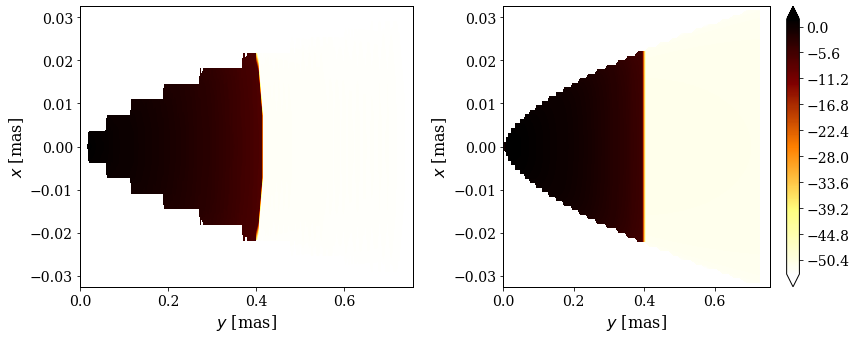

In [28]:
plt.clf()
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
ax1.set_xlabel(r"$y$ [mas]")
ax1.set_ylabel(r"$x$ [mas]")
ax1.set_xlim([0, y_map2[-1]])
ax2.set_xlim([0, y_map2[-1]])
ax1.set_ylim([x_map22[0], x_map22[-1]])
ax2.set_xlabel(r"$y$ [mas]")
ax2.set_ylabel(r"$x$ [mas]")
cmap  = plt.cm.afmhot_r
#cmap.set_label(r"$S_\nu$ [mJy]")
CS = ax1.contourf( y_map2, x_map22, np.log10(F_map2), cmap=cmap, levels=300, extend="both")
CS2 = ax2.contourf( y_map, x_map, np.log10(F_map), cmap=cmap, levels=300, extend="both")

plt.tight_layout()
fig.colorbar(CS)

#### Convolved flux map:

<Figure size 432x288 with 0 Axes>

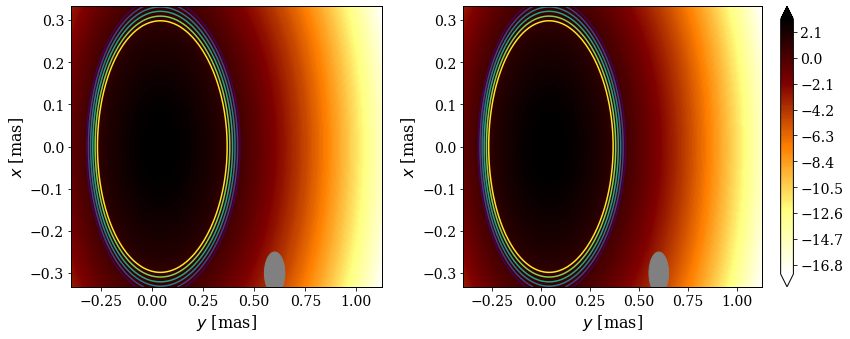

In [29]:
from matplotlib.patches import Ellipse

plt.clf()
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={'width_ratios': [1, 1.2]})
ax1.set_xlabel(r"$y$ [mas]")
ax1.set_ylabel(r"$x$ [mas]")
ax2.set_xlabel(r"$y$ [mas]")
ax2.set_ylabel(r"$x$ [mas]")
ax1.set_xlim([y_c[0], y_c[-1]])
ax2.set_xlim([y_c[0], y_c[-1]])
ax1.set_ylim([x_c[0], x_c[-1]])
ax2.set_ylim([x_c[0], x_c[-1]])
cmap  = plt.cm.afmhot_r
#cmap.set_label(r"$S_\nu$ [mJy beam$^{-1}$]")
CS_conv = ax1.contourf( y_c, x_c, np.log10(F_map_c2), cmap=cmap, levels=200, extend="both")
CS_conv = ax2.contourf( y_c, x_c, np.log10(F_map_c), cmap=cmap, levels=200, extend="both")

#Agregar contornos a (1, 1.4, 2, 2.8...)*3 mJy beam^-1.
obs_cont = np.log10([1*3, 1.4*3, 2*3, 2.8*3, 4*3, 5.6*3]) # HACERLOS EN GRIS!
plot_cont = ax1.contour( y_c, x_c, np.log10(F_map_c2), levels=obs_cont, extend="both")
plot_cont2 = ax2.contour( y_c, x_c, np.log10(F_map_c), levels=obs_cont, extend="both")

el = Ellipse((0.6, -0.3), sigma_y, sigma_x, color='grey')
el2 = Ellipse((0.6, -0.3), sigma_y, sigma_x, color='grey')

ax1.add_patch(el)
ax2.add_patch(el2)

plt.tight_layout()
fig.colorbar( CS_conv)